## Project 2: traditional data fusion

### Creation of the enviroment for the MMDet3D library

In [1]:
import os
from google.colab import drive

# 1. Mount Google Drive
drive.mount('/content/drive')

# 2. Configurazione PATH Miniconda
if not os.path.exists("/usr/local/miniconda"):
    print(" Configuration of the Conda environment for the first time...")
    !wget -q https://repo.anaconda.com/miniconda/Miniconda3-latest-Linux-x86_64.sh -O /tmp/miniconda.sh
    !bash /tmp/miniconda.sh -b -p /usr/local/miniconda
    os.environ["PATH"] = "/usr/local/miniconda/bin:" + os.environ["PATH"]

    !conda tos accept --override-channels --channel https://repo.anaconda.com/pkgs/main
    !conda tos accept --override-channels --channel https://repo.anaconda.com/pkgs/r
    
    !conda create -n openmmlab python=3.10 -y
    !conda run -n openmmlab pip install "numpy<2" torch==2.0.1 torchvision==0.15.2 --index-url https://download.pytorch.org/whl/cu118
    !conda run -n openmmlab pip install -U openmim
    !conda run -n openmmlab mim install mmengine "mmcv>=2.0.0rc4,<2.1.0" "mmdet>=3.0.0,<3.1.0"
    
    if not os.path.exists('/content/mmdetection3d'):
        !git clone https://github.com/open-mmlab/mmdetection3d.git -b dev-1.x /content/mmdetection3d
        %cd /content/mmdetection3d
        !conda run -n openmmlab pip install --no-build-isolation .
        %cd /content
    !conda run -n openmmlab pip install "numpy<2"
else:
    os.environ["PATH"] = "/usr/local/miniconda/bin:" + os.environ["PATH"]
    print(" Conda environment is already ready!")
    
    print(" Conda environment and OpenMMLab are active!")

Mounted at /content/drive
 Configuration of the Conda environment for the first time...
PREFIX=/usr/local/miniconda
Unpacking bootstrapper...
Unpacking payload...

Installing base environment...

Preparing transaction: ...working... done
Executing transaction: ...working... done
installation finished.
    You currently have a PYTHONPATH environment variable set. This may cause
    unexpected behavior when running the Python interpreter in Miniconda3.
    For best results, please verify that your PYTHONPATH only points to
    directories of packages that are compatible with the Python interpreter
    in Miniconda3: /usr/local/miniconda
accepted Terms of Service for https://repo.anaconda.com/pkgs/main
accepted Terms of Service for https://repo.anaconda.com/pkgs/r
Jupyter detected...
2 channel Terms of Service accepted
Retrieving notices: done
Channels:
 - defaults
Platform: linux-64
Solving environment: done

## Package Plan ##

  environment location: /usr/local/miniconda/envs/openmmlab

### Cloning the repo from GitHub

In [2]:
import os
from google.colab import drive

# Mount Google Drive
drive.mount('/content/drive')

%cd /content
if not os.path.exists('/content/3D_Perception'):
    !git clone https://github.com/giacomosalvatori03/3D_Perception.git
%cd /content/3D_Perception
!git pull
!git fetch origin
!git checkout project2-fusion
!git pull origin project2-fusion

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
/content
Cloning into '3D_Perception'...
remote: Enumerating objects: 668, done.
remote: Counting objects: 100% (54/54), done.
remote: Compressing objects: 100% (36/36), done.
remote: Total 668 (delta 30), reused 41 (delta 18), pack-reused 614 (from 1)
Receiving objects: 100% (668/668), 26.87 MiB | 20.94 MiB/s, done.
Resolving deltas: 100% (414/414), done.
/content/3D_Perception
Already up to date.
branch 'project2-fusion' set up to track 'origin/project2-fusion'.
Switched to a new branch 'project2-fusion'
From https://github.com/giacomosalvatori03/3D_Perception
 * branch            project2-fusion -> FETCH_HEAD
Already up to date.


### LiDAR validation with lower confidance

#### Baseline

In [2]:
%%bash
source /usr/local/miniconda/bin/activate openmmlab

cd /content/3D_Perception
git pull

python validate_lidar.py \
    --data_path /content/drive/MyDrive/3D_Perception/data/kitti_validation \
    --save_dir /content/drive/MyDrive/3D_Perception/experiments_camera \
    --subsample_mode none \
    --max_samples 500 \
    --conf_thresh 0.15

Already up to date.
 Loading PointPillars on cuda:0
Loads checkpoint by local backend from path: /content/3D_Perception/weights/pointpillar_kitti.pth
 Classes mapping extracted from the model: ['Pedestrian', 'Cyclist', 'Car']

 Starting PointPillars Inference [BASELINE_100PERC] | Samples: 500/3769
 Destination for .txt files on Drive: /content/drive/MyDrive/3D_Perception/experiments_camera/baseline_100perc

 Inference and saving completed successfully!
  • Predictions saved in: /content/drive/MyDrive/3D_Perception/experiments_camera/baseline_100perc/pred_labels
  • Ground Truth saved in: /content/drive/MyDrive/3D_Perception/experiments_camera/baseline_100perc/gt_labels


/usr/local/miniconda/envs/openmmlab/lib/python3.10/site-packages/mmdet3d/models/dense_heads/anchor3d_head.py:94: UserWarning: dir_offset and dir_limit_offset will be depressed and be incorporated into box coder in the future
  warnings.warn(
Processing Frames:   0%|          | 0/500 [00:00<?, ?it/s]/usr/local/miniconda/envs/openmmlab/lib/python3.10/site-packages/torch/functional.py:504: UserWarning: torch.meshgrid: in an upcoming release, it will be required to pass the indexing argument. (Triggered internally at ../aten/src/ATen/native/TensorShape.cpp:3483.)
  return _VF.meshgrid(tensors, **kwargs)  # type: ignore[attr-defined]
Processing Frames: 100%|██████████| 500/500 [10:29<00:00,  1.26s/it]


#### Random drop 75%

In [3]:
%%bash
source /usr/local/miniconda/bin/activate openmmlab

cd /content/3D_Perception
git pull

python validate_lidar.py \
    --data_path /content/drive/MyDrive/3D_Perception/data/kitti_validation \
    --save_dir /content/drive/MyDrive/3D_Perception/experiments_camera \
    --subsample_mode random \
    --subsample_ratio 0.75 \
    --max_samples 500 \
    --conf_thresh 0.15

Already up to date.
 Loading PointPillars on cuda:0
Loads checkpoint by local backend from path: /content/3D_Perception/weights/pointpillar_kitti.pth
 Classes mapping extracted from the model: ['Pedestrian', 'Cyclist', 'Car']

 Starting PointPillars Inference [RANDOM_75PERC] | Samples: 500/3769
 Destination for .txt files on Drive: /content/drive/MyDrive/3D_Perception/experiments_camera/random_75perc

 Inference and saving completed successfully!
  • Predictions saved in: /content/drive/MyDrive/3D_Perception/experiments_camera/random_75perc/pred_labels
  • Ground Truth saved in: /content/drive/MyDrive/3D_Perception/experiments_camera/random_75perc/gt_labels


/usr/local/miniconda/envs/openmmlab/lib/python3.10/site-packages/mmdet3d/models/dense_heads/anchor3d_head.py:94: UserWarning: dir_offset and dir_limit_offset will be depressed and be incorporated into box coder in the future
  warnings.warn(
Processing Frames:   0%|          | 0/500 [00:00<?, ?it/s]/usr/local/miniconda/envs/openmmlab/lib/python3.10/site-packages/torch/functional.py:504: UserWarning: torch.meshgrid: in an upcoming release, it will be required to pass the indexing argument. (Triggered internally at ../aten/src/ATen/native/TensorShape.cpp:3483.)
  return _VF.meshgrid(tensors, **kwargs)  # type: ignore[attr-defined]
Processing Frames: 100%|██████████| 500/500 [00:29<00:00, 16.76it/s]


#### Random drop 50%

In [4]:
%%bash
source /usr/local/miniconda/bin/activate openmmlab

cd /content/3D_Perception
git pull

python validate_lidar.py \
    --data_path /content/drive/MyDrive/3D_Perception/data/kitti_validation \
    --save_dir /content/drive/MyDrive/3D_Perception/experiments_camera \
    --subsample_mode random \
    --subsample_ratio 0.50 \
    --max_samples 500 \
    --conf_thresh 0.15

Already up to date.
 Loading PointPillars on cuda:0
Loads checkpoint by local backend from path: /content/3D_Perception/weights/pointpillar_kitti.pth
 Classes mapping extracted from the model: ['Pedestrian', 'Cyclist', 'Car']

 Starting PointPillars Inference [RANDOM_50PERC] | Samples: 500/3769
 Destination for .txt files on Drive: /content/drive/MyDrive/3D_Perception/experiments_camera/random_50perc

 Inference and saving completed successfully!
  • Predictions saved in: /content/drive/MyDrive/3D_Perception/experiments_camera/random_50perc/pred_labels
  • Ground Truth saved in: /content/drive/MyDrive/3D_Perception/experiments_camera/random_50perc/gt_labels


/usr/local/miniconda/envs/openmmlab/lib/python3.10/site-packages/mmdet3d/models/dense_heads/anchor3d_head.py:94: UserWarning: dir_offset and dir_limit_offset will be depressed and be incorporated into box coder in the future
  warnings.warn(
Processing Frames:   0%|          | 0/500 [00:00<?, ?it/s]/usr/local/miniconda/envs/openmmlab/lib/python3.10/site-packages/torch/functional.py:504: UserWarning: torch.meshgrid: in an upcoming release, it will be required to pass the indexing argument. (Triggered internally at ../aten/src/ATen/native/TensorShape.cpp:3483.)
  return _VF.meshgrid(tensors, **kwargs)  # type: ignore[attr-defined]
Processing Frames: 100%|██████████| 500/500 [00:28<00:00, 17.41it/s]


#### Random drop 25%

In [5]:
%%bash
source /usr/local/miniconda/bin/activate openmmlab

cd /content/3D_Perception
git pull

python validate_lidar.py \
    --data_path /content/drive/MyDrive/3D_Perception/data/kitti_validation \
    --save_dir /content/drive/MyDrive/3D_Perception/experiments_camera \
    --subsample_mode random \
    --subsample_ratio 0.50 \
    --max_samples 500 \
    --conf_thresh 0.15

Already up to date.
 Loading PointPillars on cuda:0
Loads checkpoint by local backend from path: /content/3D_Perception/weights/pointpillar_kitti.pth
 Classes mapping extracted from the model: ['Pedestrian', 'Cyclist', 'Car']

 Starting PointPillars Inference [RANDOM_50PERC] | Samples: 500/3769
 Destination for .txt files on Drive: /content/drive/MyDrive/3D_Perception/experiments_camera/random_50perc

 Inference and saving completed successfully!
  • Predictions saved in: /content/drive/MyDrive/3D_Perception/experiments_camera/random_50perc/pred_labels
  • Ground Truth saved in: /content/drive/MyDrive/3D_Perception/experiments_camera/random_50perc/gt_labels


/usr/local/miniconda/envs/openmmlab/lib/python3.10/site-packages/mmdet3d/models/dense_heads/anchor3d_head.py:94: UserWarning: dir_offset and dir_limit_offset will be depressed and be incorporated into box coder in the future
  warnings.warn(
Processing Frames:   0%|          | 0/500 [00:00<?, ?it/s]/usr/local/miniconda/envs/openmmlab/lib/python3.10/site-packages/torch/functional.py:504: UserWarning: torch.meshgrid: in an upcoming release, it will be required to pass the indexing argument. (Triggered internally at ../aten/src/ATen/native/TensorShape.cpp:3483.)
  return _VF.meshgrid(tensors, **kwargs)  # type: ignore[attr-defined]
Processing Frames: 100%|██████████| 500/500 [00:27<00:00, 18.16it/s]


#### Beam drop 32

In [6]:
%%bash
source /usr/local/miniconda/bin/activate openmmlab

cd /content/3D_Perception
git pull

python validate_lidar.py \
    --data_path /content/drive/MyDrive/3D_Perception/data/kitti_validation \
    --save_dir /content/drive/MyDrive/3D_Perception/experiments_camera \
    --subsample_mode beam \
    --num_beams 32 \
    --max_samples 500 \
    --conf_thresh 0.15

Already up to date.
 Loading PointPillars on cuda:0
Loads checkpoint by local backend from path: /content/3D_Perception/weights/pointpillar_kitti.pth
 Classes mapping extracted from the model: ['Pedestrian', 'Cyclist', 'Car']

 Starting PointPillars Inference [BEAM_32RINGS] | Samples: 500/3769
 Destination for .txt files on Drive: /content/drive/MyDrive/3D_Perception/experiments_camera/beam_32rings

 Inference and saving completed successfully!
  • Predictions saved in: /content/drive/MyDrive/3D_Perception/experiments_camera/beam_32rings/pred_labels
  • Ground Truth saved in: /content/drive/MyDrive/3D_Perception/experiments_camera/beam_32rings/gt_labels


/usr/local/miniconda/envs/openmmlab/lib/python3.10/site-packages/mmdet3d/models/dense_heads/anchor3d_head.py:94: UserWarning: dir_offset and dir_limit_offset will be depressed and be incorporated into box coder in the future
  warnings.warn(
Processing Frames:   0%|          | 0/500 [00:00<?, ?it/s]/usr/local/miniconda/envs/openmmlab/lib/python3.10/site-packages/torch/functional.py:504: UserWarning: torch.meshgrid: in an upcoming release, it will be required to pass the indexing argument. (Triggered internally at ../aten/src/ATen/native/TensorShape.cpp:3483.)
  return _VF.meshgrid(tensors, **kwargs)  # type: ignore[attr-defined]
Processing Frames: 100%|██████████| 500/500 [00:28<00:00, 17.33it/s]


#### Beam drop 16

In [7]:
%%bash
source /usr/local/miniconda/bin/activate openmmlab

cd /content/3D_Perception
git pull

python validate_lidar.py \
    --data_path /content/drive/MyDrive/3D_Perception/data/kitti_validation \
    --save_dir /content/drive/MyDrive/3D_Perception/experiments_camera \
    --subsample_mode beam \
    --num_beams 16 \
    --max_samples 500 \
    --conf_thresh 0.15

Already up to date.
 Loading PointPillars on cuda:0
Loads checkpoint by local backend from path: /content/3D_Perception/weights/pointpillar_kitti.pth
 Classes mapping extracted from the model: ['Pedestrian', 'Cyclist', 'Car']

 Starting PointPillars Inference [BEAM_16RINGS] | Samples: 500/3769
 Destination for .txt files on Drive: /content/drive/MyDrive/3D_Perception/experiments_camera/beam_16rings

 Inference and saving completed successfully!
  • Predictions saved in: /content/drive/MyDrive/3D_Perception/experiments_camera/beam_16rings/pred_labels
  • Ground Truth saved in: /content/drive/MyDrive/3D_Perception/experiments_camera/beam_16rings/gt_labels


/usr/local/miniconda/envs/openmmlab/lib/python3.10/site-packages/mmdet3d/models/dense_heads/anchor3d_head.py:94: UserWarning: dir_offset and dir_limit_offset will be depressed and be incorporated into box coder in the future
  warnings.warn(
Processing Frames:   0%|          | 0/500 [00:00<?, ?it/s]/usr/local/miniconda/envs/openmmlab/lib/python3.10/site-packages/torch/functional.py:504: UserWarning: torch.meshgrid: in an upcoming release, it will be required to pass the indexing argument. (Triggered internally at ../aten/src/ATen/native/TensorShape.cpp:3483.)
  return _VF.meshgrid(tensors, **kwargs)  # type: ignore[attr-defined]
Processing Frames: 100%|██████████| 500/500 [00:27<00:00, 18.08it/s]


In [1]:
import sys

!pip install ultralytics huggingface_hub -q

sys.path.insert(0, "/content/3D_Perception")
from src import CameraDetector

# Initialize the 2D detector with KITTI weights
detector_2d = CameraDetector(conf_thresh=0.25)

# Test inference on a validation frame
sample_img_path = (
    "/content/drive/MyDrive/3D_Perception/data/kitti_validation/image_2/000008.png"
)
detections_2d = detector_2d.detect(sample_img_path)

print(f"\n Found {len(detections_2d)} 2D detections in the image:")
for det in detections_2d:
    bbox = [round(v, 1) for v in det["bbox_2d"]]
    print(
        f"  - [{det['type']}] Confidence: {det['score']:.2f} | 2D BBox: {bbox}"
    )

 Downloading/Loading KITTI YOLOv8 model from HF: dronefreak/kitti-yolov8m/best.pt...


/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:138: UserWarning: 
Error while fetching `HF_TOKEN` secret value from your vault: 'Requesting secret HF_TOKEN timed out. Secrets can only be fetched when running from the Colab UI.'.
  warnings.warn(f"\nError while fetching `HF_TOKEN` secret value from your vault: '{str(e)}'.")


 Loaded KITTI 2D Detector. Registered classes: {0: 'Car', 1: 'Cyclist', 2: 'Misc', 3: 'Pedestrian', 4: 'Person_sitting', 5: 'Tram', 6: 'Truck', 7: 'Van'}

 Found 9 2D detections in the image:
  - [Car] Confidence: 0.92 | 2D BBox: [884.5, 177.8, 954.4, 241.1]
  - [Car] Confidence: 0.89 | 2D BBox: [738.2, 168.2, 788.1, 209.1]
  - [Car] Confidence: 0.88 | 2D BBox: [594.4, 175.5, 719.0, 264.5]
  - [Car] Confidence: 0.86 | 2D BBox: [945.7, 200.9, 1242.0, 375.0]
  - [Car] Confidence: 0.83 | 2D BBox: [335.7, 173.7, 618.6, 366.1]
  - [Car] Confidence: 0.83 | 2D BBox: [861.7, 173.9, 887.3, 195.8]
  - [Car] Confidence: 0.81 | 2D BBox: [0.1, 174.4, 400.3, 374.6]
  - [Car] Confidence: 0.72 | 2D BBox: [765.9, 170.9, 803.8, 201.6]
  - [Car] Confidence: 0.30 | 2D BBox: [879.2, 181.7, 936.1, 228.3]


### Camera-only evaluation

In [2]:
!pip install ultralytics huggingface_hub -q

import sys
sys.path.insert(0, "/content/3D_Perception")

from validate_camera import CameraValidator

# Initialize the validation class
validator = CameraValidator(
    data_path="/content/drive/MyDrive/3D_Perception/data/kitti_validation",
    save_dir="/content/drive/MyDrive/3D_Perception/experiments_camera",
    conf_thresh=0.25,
)

# Run validation on all samples (or on max_samples for quick tests)
validator.validate(exp_name="yolov8m_baseline_2d", max_samples=500)

 Downloading/Loading KITTI YOLOv8 model from HF: dronefreak/kitti-yolov8m/best.pt...


/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:138: UserWarning: 
Error while fetching `HF_TOKEN` secret value from your vault: 'Requesting secret HF_TOKEN timed out. Secrets can only be fetched when running from the Colab UI.'.
  warnings.warn(f"\nError while fetching `HF_TOKEN` secret value from your vault: '{str(e)}'.")


 Loaded KITTI 2D Detector. Registered classes: {0: 'Car', 1: 'Cyclist', 2: 'Misc', 3: 'Pedestrian', 4: 'Person_sitting', 5: 'Tram', 6: 'Truck', 7: 'Van'}

 Starting 2D Camera Validation [YOLOV8M_BASELINE_2D] | Samples: 500/3769
 Output destination: /content/drive/MyDrive/3D_Perception/experiments_camera/yolov8m_baseline_2d


Processing 2D Frames: 100%|██████████| 500/500 [15:16<00:00,  1.83s/it]


 2D Validation completed successfully!
  • Predictions saved in: /content/drive/MyDrive/3D_Perception/experiments_camera/yolov8m_baseline_2d/pred_labels
  • Ground Truths saved in: /content/drive/MyDrive/3D_Perception/experiments_camera/yolov8m_baseline_2d/gt_labels


In [4]:
import sys

sys.path.insert(0, "/content/3D_Perception")

from src import CameraEvaluator

# Initialize the 2D evaluator
evaluator_2d = CameraEvaluator()

# Compute the evaluation metrics on the 2D predictions
exp_dir = "/content/drive/MyDrive/3D_Perception/experiments_camera/yolov8m_baseline_2d"
df_results = evaluator_2d.evaluate(exp_dir)


 OVERALL 2D DETECTION mAP40 [yolov8m_baseline_2d]



,Easy,Moderate,Hard
Class,,,
Car,45.77%,64.57%,65.24%
Pedestrian,59.36%,52.33%,46.47%
Cyclist,50.44%,38.73%,37.25%



 Reports saved in '/content/drive/MyDrive/3D_Perception/experiments_camera/yolov8m_baseline_2d': .json, .csv, .md, .tex


### Visualize the camera-only

 2D Grid Visualization saved to Drive: /content/drive/MyDrive/3D_Perception/experiments_camera/yolov8m_baseline_2d/visualizations/summary_2d_grid.png


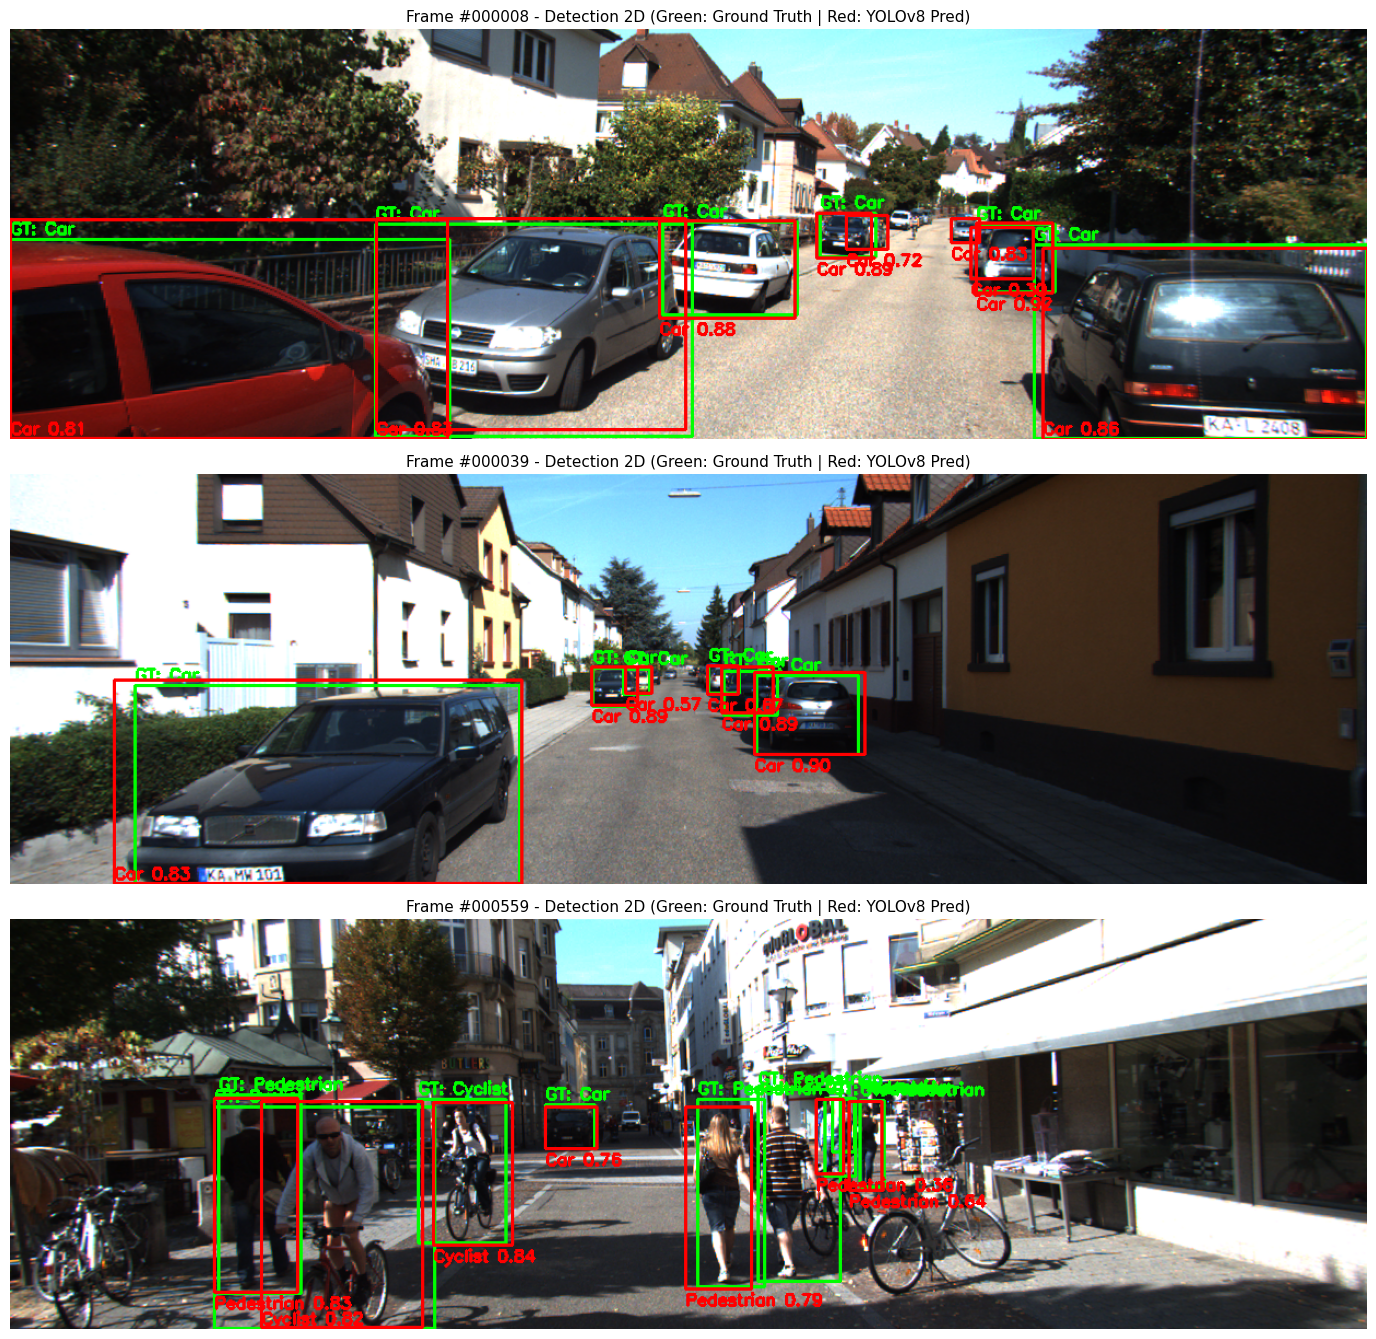

In [2]:
import sys

sys.path.insert(0, "/content/3D_Perception")

from scripts.camera_visualizer import CameraVisualizer

visualizer_2d = CameraVisualizer(
    data_path="/content/drive/MyDrive/3D_Perception/data/kitti_validation"
)

exp_dir = "/content/drive/MyDrive/3D_Perception/experiments_camera/yolov8m_baseline_2d"

# Visualize 3 significant samples from the experiment
visualizer_2d.visualize_experiment_2d(
    exp_dir=exp_dir,
    sample_ids=["000008", "000039", "000559"],  # You can pass specific IDs or leave as None
    save_plots=True,
)

## Perform the traditional fusion

### Baseline evaluation

In [ ]:
import sys

sys.path.insert(0, "/content/3D_Perception")

from scripts.lidar_evaluator import KittiEvaluator
from validate_fusion import FusionValidator

# Initialize the FusionValidator with the appropriate parameters
fusion_val = FusionValidator(
    data_path="/content/drive/MyDrive/3D_Perception/data/kitti_validation",
    iou_thresh_2d=0.30,
    alpha_boost=0.25,
    final_conf_thresh=0.25,
)

# Perform the fusion between 3D LiDAR predictions and 2D Camera predictions
fusion_val.run_fusion(
    lidar_exp_dir="/content/drive/MyDrive/3D_Perception/experiments_camera/baseline_100perc",
    camera_exp_dir="/content/drive/MyDrive/3D_Perception/experiments_camera/yolov8m_baseline_2d",
    output_exp_dir="/content/drive/MyDrive/3D_Perception/experiments_fusion/fusion_baseline_100perc",
)

# Compute the final 3D mAP40 on the fused results
evaluator_3d = KittiEvaluator()
df_fusion = evaluator_3d.evaluate(
    "/content/drive/MyDrive/3D_Perception/experiments_fusion/fusion_baseline_100perc"
)